# Best of N on round-1 pairs

Prof. Lyzinski asked for a simple, reliable way to pick seeds that beats random. The rule tested here: draw N random seed sets of the budget's size, score each one from graph A with the pooled weights from `multi_pair_models.ipynb`, and query the highest-scoring set. It runs on round 1's pairs, which the weights never saw, at round 1's budgets, and is compared with round 1's stored results on the same pairs.

**Design** (details in `best_of_n.py`)

| | |
|---|---|
| Pairs | Round 1's 20 pairs per algorithm and graph model, regenerated and checked against round 1's hashes |
| Budgets | Round 1's six per setting |
| Score | Weighted sum of degree, harmonic, pair mass and uniqueness. Each feature is measured in SDs of the random sets drawn on the same graph at the same budget. The pooled weights (one set per setting) were fitted at one budget, so the other budgets also test whether they carry over. |
| New rules | Best of 100 and best of 1,000 by the score (the 100 are the first of the 1,000 draws), and best of 1,000 by degree alone, as a control |
| Runs | Round 1's solver settings and solver seeds: one run for percolation and GOAT; FAQ restarts up to 3 times and stops at the first success |
| Compared with | Round 1's random, top degree, and its best rule per setting (highest mean success over the budgets, picked after the fact, which favours it) |

**GOAT at r = 100 (robustness check, section 8).** Round 1 ran GOAT with transport regulariser r = 300 on PAPER and Chung–Lu, which was tuned for those graphs. graspologic's default is r = 100. `run_r100()` reruns GOAT on PAPER and Chung–Lu at r = 100 for round 1's rules and the screened rules, with the same pairs, sets, budgets and solver seeds. r = 300 stays the main setting.

**Run time.** About 1.5 hours with 3 pairs at a time: percolation about 5 min, GOAT about 25 min, FAQ about 1 h. GOAT at r = 100 adds about 40 min. Each pair is saved when it finishes, and rerunning skips finished pairs.

| Section | Content |
|---|---|
| 1 | Checks |
| 2 | Success by budget, head to head |
| 3 | Mean success and queries needed |
| 4 | Pair-by-pair comparisons |
| 5 | Where the hand-made rules sit on the score |
| 6 | Draft NetSci figure |
| 7 | Individual seed sets, as in section 10 of `rule_comparison.ipynb`, with best of N added |
| 8 | GOAT at r = 100 against r = 300 |

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

from selection_rule_comparison.archive import best_of_n as BN

pd.set_option('display.max_rows', 200)

RUN_COLLECTION = True                                 # False: only analyse saved results
ALGORITHMS_TO_RUN = ['percolation', 'goat', 'faq']    # remove any to skip it
RUN_R100 = True                                       # GOAT at r = 100 on PAPER and Chung-Lu (section 8)
JOBS = 3                                              # pairs run in parallel

# Line styles: greys and black for round 1's references, orange for round 1's best rule, blues for best of N.
STYLE = {
    'random': dict(color='#9a9a9a', linewidth=1.6, marker='o', markersize=4, label='random'),
    'top_degree': dict(color='#2b2b2b', linewidth=1.8, marker='s', markersize=4, label='top degree'),
    'round1_best': dict(color='#eb6834', linewidth=1.8, marker='^', markersize=5, label="round 1's best rule"),
    'degree_1000': dict(color='#6b6b6b', linewidth=1.4, linestyle='--', marker='x', markersize=5,
                        label='best of 1,000 by degree'),
    'best_100': dict(color='#5598e7', linewidth=1.8, marker='o', markersize=4, label='best of 100'),
    'best_1000': dict(color='#1c5cab', linewidth=2.2, marker='o', markersize=5, label='best of 1,000'),
}

## Run

The cell below prints an estimate, then one line per finished pair. It runs the main experiment first (pairs already done are skipped), then GOAT at r = 100. The interrupt button stops the workers too.

To run in a terminal instead, from the repository root:
- `python -m selection_rule_comparison.best_of_n` runs the main experiment.
- `python -m selection_rule_comparison.best_of_n --r100` runs GOAT at r = 100.
- `--status` shows how far each one is. Ctrl-C stops a run.

Then set `RUN_COLLECTION = False` and `RUN_R100 = False` here to analyse.

In [2]:
if RUN_COLLECTION:
    BN.run_all(ALGORITHMS_TO_RUN, jobs=JOBS)
if RUN_R100:
    BN.run_r100(jobs=JOBS)
display(BN.status())
display(BN.r100_status())

All pairs are done. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/best_of_n
GOAT at r = 100: all pairs are done. Results are in /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/best_of_n/goat_r100


pairs planned  pairs done
algorithm   model                              
Percolation ER                   20          20
            PAPER                20          20
            Chung-Lu             20          20
GOAT        ER                   20          20
            PAPER                20          20
            Chung-Lu             20          20
SGM (FAQ)   ER                   20          20
            PAPER                20          20
            Chung-Lu             20          20

pairs planned  pairs done
algorithm     model                              
GOAT, r = 100 PAPER                20          20
              Chung-Lu             20          20

## 1. Checks

- **Pairs.** Every pair was regenerated and matched round 1's stored hashes; a mismatch stops the run.
- **Top degree.** Round 1's top-degree sets were run again on pairs 0 and 1, so every run should be identical to round 1. This confirms that the new rules meet round 1's stored results on equal terms.
- **Same pick.** How often best of 100 chose the same set as best of 1,000, and how often screening by degree chose the same set as the score.

In [3]:
runs = BN.read_runs()
display(BN.check_table(runs))

picks = runs[(runs['restart'] == 0) & runs['rule'].isin(BN.NEW_RULES)].pivot_table(
    index=['algorithm', 'model', 'pair_index', 'budget'], columns='rule', values='seed_vertices', aggfunc='first')
same = pd.DataFrame({
    'best of 100 = best of 1,000': (picks['best_100'] == picks['best_1000']).groupby(level=[0, 1]).mean(),
    'by degree = best of 1,000': (picks['degree_1000'] == picks['best_1000']).groupby(level=[0, 1]).mean(),
})
same.index = [f"{BN.ALGORITHM_LABELS[a]} {BN.MODEL_LABELS[m]}" for a, m in same.index]
display(same.round(2))

runs compared  identical to round 1
algorithm   model                                        
Percolation ER                   12                    12
            PAPER                12                    12
            Chung-Lu             12                    12
GOAT        ER                   12                    12
            PAPER                12                    12
            Chung-Lu             12                    12
SGM (FAQ)   ER                   23                    23
            PAPER                25                    25
            Chung-Lu             24                    24

,"best of 100 = best of 1,000","by degree = best of 1,000"
SGM (FAQ) Chung-Lu,0.14,0.06
SGM (FAQ) PAPER,0.12,0.78
SGM (FAQ) ER,0.08,0.38
GOAT Chung-Lu,0.11,0.00
GOAT PAPER,0.08,0.03
GOAT ER,0.08,0.41
Percolation Chung-Lu,0.08,0.23
Percolation PAPER,0.11,0.08
Percolation ER,0.10,0.12


## 2. Success by budget, head to head

Each panel shows the share of the 20 pairs where each rule's seed set succeeded, at each of round 1's budgets. A curve that rises earlier needs fewer queries.
- **Grey:** random. **Black:** top degree. **Orange:** round 1's best rule in that setting, named under the panel's title.
- **Light and dark blue:** best of 100 and best of 1,000 by the weighted score. **Dashed grey:** best of 1,000 by degree alone.

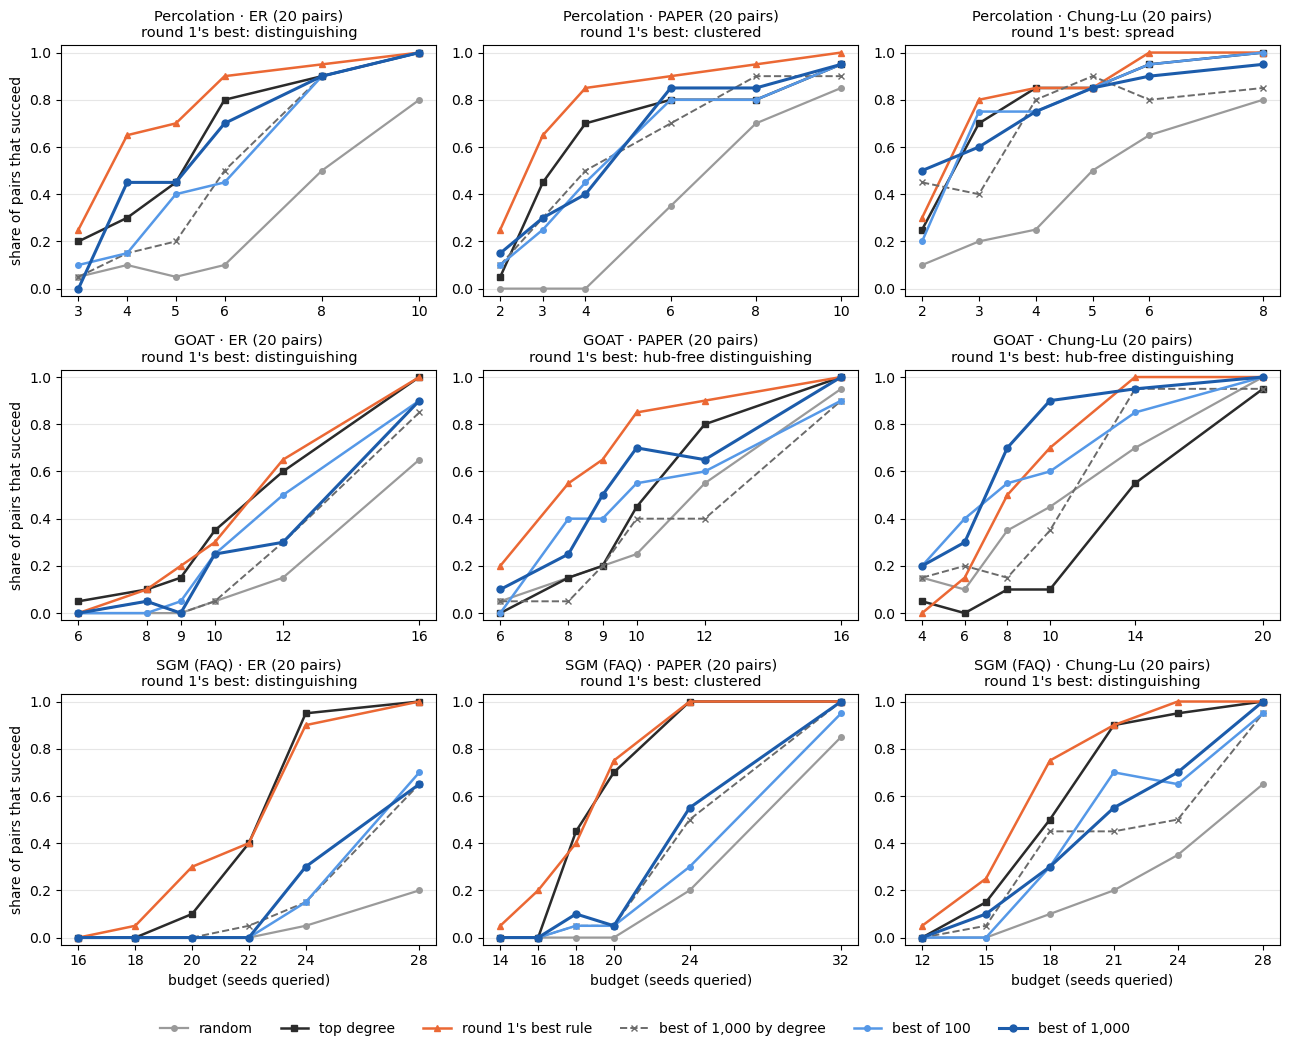

In [4]:
ev = BN.load_evaluations()
queries = BN.queries_needed(ev)
best = BN.round1_best(ev, queries)
curves = BN.success_curves(ev)

algorithms = [a for a in BN.ALGORITHMS if a in set(ev['algorithm'])]
fig, axes = plt.subplots(len(algorithms), 3, figsize=(13, 3.5 * len(algorithms)), squeeze=False)
for row, algorithm in enumerate(algorithms):
    for column, model in enumerate(BN.MODELS):
        ax = axes[row, column]
        part = curves[(curves['algorithm'] == algorithm) & (curves['model'] == model)]
        if part.empty:
            ax.set_visible(False)
            continue
        for key, style in STYLE.items():
            rule = best[(algorithm, model)] if key == 'round1_best' else key
            line = part[part['rule'] == rule].sort_values('budget')
            if not line.empty:
                ax.plot(line['budget'], line['success'], **{k: v for k, v in style.items() if k != 'label'})
        n = ev.loc[(ev['algorithm'] == algorithm) & (ev['model'] == model), 'pair_index'].nunique()
        ax.set_title(f"{BN.ALGORITHM_LABELS[algorithm]} · {BN.MODEL_LABELS[model]} ({n} pairs)\n"
                     f"round 1's best: {BN.rule_label(best[(algorithm, model)])}", fontsize=10.5)
        ax.set_xticks(sorted(part['budget'].unique()))
        ax.set_ylim(-0.03, 1.03)
        ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
        ax.set_axisbelow(True)
    axes[row, 0].set_ylabel('share of pairs that succeed')
for ax in axes[-1]:
    ax.set_xlabel('budget (seeds queried)')
handles = [Line2D([0], [0], **{k: v for k, v in style.items()}) for style in STYLE.values()]
fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 3. Mean success and queries needed

- **Mean success over budgets:** the share of round 1's budgets at which the rule succeeded, averaged over pairs, with a 95% bootstrap interval over pairs.
- **Mean queries needed:** the smallest budget at which the rule succeeded on a pair. A pair where it never succeeded counts as one grid step past the largest budget.

In [5]:
display(BN.summary_table(ev, queries, best))

pairs  \
algorithm   model    rule                                              
Percolation ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
            PAPER    random                                       20   
                     top degree                                   20   
                     clustered (round 1's best)                   20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     spread (round 1's best)                      20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
GOAT        ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
            PAPER    random                                       20   
                     top degree                                   20   
                     hub-free distinguishing (round 1's best)     20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     hub-free distinguishing (round 1's best)     20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
SGM (FAQ)   ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
            PAPER    random                                       20   
                     top degree                                   20   
                     clustered (round 1's best)                   20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 100                                  20   
                     best of 1,000                                20   
                     best of 1,000 by degree                      20   

                              

## 4. Pair-by-pair comparisons

Each row compares two rules on the same pairs.
- **Needs fewer / same / more queries:** the number of pairs where the first rule needed fewer, the same, or more queries than the second.
- **p:** a sign test of fewer against more.
- **Change in queries / change in mean success:** the average pair-by-pair difference (first rule minus second), with a 95% bootstrap interval over pairs. A negative change in queries or a positive change in success favours the first rule.

Round 1's best rule was picked after the fact on these same pairs, so that comparison favours it.

In [6]:
comparisons = BN.comparison_table(ev, queries, best)
for rule in ['best of 1,000', 'best of 100']:
    print(rule.capitalize(), 'against the others:')
    display(comparisons.xs(rule, level='rule'))

Best of 1,000 against the others:


pairs  \
algorithm   model    against                                           
Percolation ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 1,000 by degree                      20   
            PAPER    random                                       20   
                     top degree                                   20   
                     clustered (round 1's best)                   20   
                     best of 1,000 by degree                      20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     spread (round 1's best)                      20   
                     best of 1,000 by degree                      20   
GOAT        ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 1,000 by degree                      20   
            PAPER    random                                       20   
                     top degree                                   20   
                     hub-free distinguishing (round 1's best)     20   
                     best of 1,000 by degree                      20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     hub-free distinguishing (round 1's best)     20   
                     best of 1,000 by degree                      20   
SGM (FAQ)   ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 1,000 by degree                      20   
            PAPER    random                                       20   
                     top degree                                   20   
                     clustered (round 1's best)                   20   
                     best of 1,000 by degree                      20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
                     best of 1,000 by degree                      20   

                                                              needs fewer / same / more queries  \
algorithm   model    against                                                                      
Percolation ER       random                                                          18 / 1 / 1   
                     top degree                                                       8 / 4 / 8   
                     distinguishing (round 1's best)                                 4 / 5 / 11   
                     best of 1,000 by degree                                         13 / 4 / 3   
            PAPER    random                                                          17 / 2 / 1   
                     top degree                                                      5 / 5 / 10   
                     clustered (round 1's best)                                      6 / 1 / 13   
                     best of 1,000 by degree                                          7 / 7 / 6   
            Chung-Lu random                                                          17 / 0 / 3   
                     top degree                                                       9 / 5 / 6   
                     spread (round 1's best)                                          8 / 5 / 7   
                     best of 1,000 by d

Best of 100 against the others:


pairs  \
algorithm   model    against                                           
Percolation ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
            PAPER    random                                       20   
                     top degree                                   20   
                     clustered (round 1's best)                   20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     spread (round 1's best)                      20   
GOAT        ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
            PAPER    random                                       20   
                     top degree                                   20   
                     hub-free distinguishing (round 1's best)     20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     hub-free distinguishing (round 1's best)     20   
SGM (FAQ)   ER       random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   
            PAPER    random                                       20   
                     top degree                                   20   
                     clustered (round 1's best)                   20   
            Chung-Lu random                                       20   
                     top degree                                   20   
                     distinguishing (round 1's best)              20   

                                                              needs fewer / same / more queries  \
algorithm   model    against                                                                      
Percolation ER       random                                                          15 / 3 / 2   
                     top degree                                                       6 / 5 / 9   
                     distinguishing (round 1's best)                                 4 / 3 / 13   
            PAPER    random                                                          14 / 6 / 0   
                     top degree                                                       6 / 6 / 8   
                     clustered (round 1's best)                                      6 / 2 / 12   
            Chung-Lu random                                                          16 / 2 / 2   
                     top degree                                                       5 / 9 / 6   
                     spread (round 1's best)                                         3 / 10 / 7   
GOAT        ER       random                                                          15 / 3 / 2   
                     top degree                                                       7 / 6 / 7   
                     distinguishing (round 1's best)                                  5 / 6 / 9   
            PAPER    random                                                          13 / 4 / 3   
                     top degree                                                      10 / 7 / 3   
                     hub-free distinguishing (round 1's best)                        3 / 7 / 10   
            Chung-Lu random                                                          10 / 6 / 4   
                     top degree                                                      17 / 2 / 1   
                     hub-free distinguishing (round 1's best)                        14 / 1 /

## 5. Where the hand-made rules sit on the score

For each rule's seed sets, averaged over pairs and budgets:
- **Median score percentile:** the set's position among the 1,000 random sets drawn on the same graph at the same budget. Best of 1,000 is at 100 by construction.
- **Mean z-scores:** how many SDs of those random sets each feature lies from their average.

Round 1's rules sit far outside the range the weights were fitted on, so their scores are extrapolations. Top degree, clustered and distinguishing are typically about 6–17 SD above the average random set in degree, and up to about 35 SD in pair mass. Best of 1,000 stays within about 1–7 SD.

In [7]:
scores = BN.read_scores()
display(BN.score_positions(scores, best))

median score percentile  \
algorithm   model    rule                                                                
Percolation ER       random                                                       58.0   
                     top degree                                                  100.0   
                     distinguishing (round 1's best)                             100.0   
                     best of 100                                                  99.2   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      98.7   
            PAPER    random                                                       38.9   
                     top degree                                                  100.0   
                     clustered (round 1's best)                                  100.0   
                     best of 100                                                  99.3   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      97.9   
            Chung-Lu random                                                       54.3   
                     top degree                                                  100.0   
                     spread (round 1's best)                                     100.0   
                     best of 100                                                  99.3   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      99.5   
GOAT        ER       random                                                       40.0   
                     top degree                                                  100.0   
                     distinguishing (round 1's best)                             100.0   
                     best of 100                                                  99.3   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      99.9   
            PAPER    random                                                       40.8   
                     top degree                                                  100.0   
                     hub-free distinguishing (round 1's best)                    100.0   
                     best of 100                                                  99.4   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      90.8   
            Chung-Lu random                                                       52.5   
                     top degree                                                   92.8   
                     hub-free distinguishing (round 1's best)                    100.0   
                     best of 100                                                  99.4   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      25.9   
SGM (FAQ)   ER       random                                                       51.9   
                     top degree                                                  100.0   
                     distinguishing (round 1's best)                             100.0   
                     best of 100                                                  99.4   
                     best of 1,000                                               100.0   
                     best of 1,000 by degree                                      99.8   
            PAPER    random                                                       48.9   
             

## 6. Draft NetSci figure

This is the success-versus-score plot from `multi_pair_models.ipynb` (section 3), redrawn for a one-page abstract. Each line is one graph model. The x-axis is the score's percentile among the pair's 20,000 random seed sets, scored by a model fitted without that pair. Best of 100 lands near the 99th percentile and best of 1,000 near the 99.9th, the shaded band. Dotted lines mark each model's average random set.

The figure is saved to `data/best_of_n/figures/` as PNG (300 dpi) and PDF. Draft caption:

> *Seed sets that score higher succeed more often on graph pairs the score never saw. Success rate of seed sets binned by their score's percentile among random seed sets of the same size on the same graph (percolation: r = 2, success = at least 50% of non-seeds matched; GOAT and FAQ: graspologic, success = at least 90%). Dotted: the average random seed set. Shaded: where best of 100 to best of 1,000 picks.*

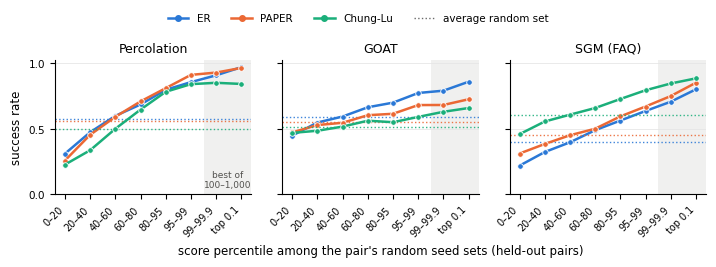

Saved /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/best_of_n/figures/netsci_success_vs_score.png and /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/best_of_n/figures/netsci_success_vs_score.pdf


,99-99.9,top 0.1,average random set
SGM (FAQ) Chung-Lu,0.84,0.88,0.60
SGM (FAQ) PAPER,0.75,0.85,0.45
SGM (FAQ) ER,0.70,0.80,0.40
GOAT Chung-Lu,0.63,0.66,0.52
GOAT PAPER,0.68,0.72,0.55
GOAT ER,0.79,0.86,0.59
Percolation Chung-Lu,0.85,0.84,0.50
Percolation PAPER,0.93,0.96,0.56
Percolation ER,0.90,0.97,0.57


In [8]:
score_lines = BN.score_curves()
figure_path = BN.OUTPUT_DIR / 'figures' / 'netsci_success_vs_score'
fig = BN.netsci_figure(score_lines, figure_path)
plt.show()
print('Saved', figure_path.with_suffix('.png'), 'and', figure_path.with_suffix('.pdf'))
top = score_lines[score_lines['bin'].isin(['99-99.9', 'top 0.1'])].pivot_table(
    index=['algorithm', 'model'], columns='bin', values='success').join(
    score_lines.groupby(['algorithm', 'model'])['random'].first())
top.index = [f"{BN.ALGORITHM_LABELS[a]} {BN.MODEL_LABELS[m]}" for a, m in top.index]
display(top.rename(columns={'random': 'average random set'}).round(2))

## 7. Individual seed sets, with best of N added

This repeats section 10 of `rule_comparison.ipynb` with the screened rules added, at one budget per setting.
- **Left panel:** the x-axis is degree (seed-to-nonseed edges per seed).
- **Right panel:** the x-axis is the pooled weighted score, the one best of N screens with.
- **y-axis:** final unseeded accuracy. For FAQ it is the run with the best objective among the restarts, as in `rule_comparison.ipynb`.

**Markers.** Each rule has its own colour and shape:
- Grey circles: random. Black squares: top degree.
- Orange: round 1's other rules, one shape each. The legend marks round 1's best rule in that setting.
- Blue circles: best of 100 (light) and best of 1,000 (dark). Green crosses: best of 1,000 by degree alone.

**Small faded markers** are single sets, one per rule per pair. **Large markers** are each rule's mean over the pairs: its mean degree or score, and its mean accuracy. Their lines are 95% bootstrap intervals over pairs. Comparing the large markers compares the rules. To see section 10's pooled means in five bins of x instead, set `SCATTER_SUMMARY = 'bins'`.

**Budget.** By default, each setting uses the budget where the mean success over all rules is closest to 50%, so outcomes vary. Set `SCATTER_BUDGETS` to pick others, `SCATTER_SETTINGS` to show fewer settings, and `SCATTER_X` to change the x-axes. Everything here reads saved results.

In [9]:
SCATTER_SETTINGS = 'all'               # 'all', or e.g. [('goat', 'chung_lu'), ('faq', 'paper_pa')]
SCATTER_BUDGETS = {}                   # e.g. {('goat', 'chung_lu'): 10}; others: mean success closest to 50%
SCATTER_X = ('f_degree', 'score')      # also 'f_harmonic', 'f_pair_mass', 'f_signature_r2', 'f_signature_r3', 'score_percentile'
SCATTER_SUMMARY = 'rules'              # 'rules': each rule's mean; 'bins': pooled means in bins of x (section 10)
SCATTER_N_BINS = 5                     # used with 'bins'
SCATTER_INCLUDE_RANDOM = True          # round 1's random sets in section 7.1
SCATTER_PAIRED_INCLUDE_RANDOM = False  # and in sections 7.2 and 7.3

seed_sets = BN.seed_set_table(ev, scores)
scatter_settings = (BN._settings(seed_sets) if SCATTER_SETTINGS == 'all'
                    else [tuple(s) for s in SCATTER_SETTINGS])
scatter_budgets = {s: SCATTER_BUDGETS.get(s, BN.scatter_budget(seed_sets, *s)) for s in scatter_settings}


def scatter_frame(algorithm, model, include_random=True):
    budget = scatter_budgets[(algorithm, model)]
    frame = seed_sets[(seed_sets['algorithm'] == algorithm) & (seed_sets['model'] == model)
                      & (seed_sets['budget'] == budget)]
    if frame.empty:
        raise ValueError(f'{algorithm}/{model}: no results at budget {budget}; '
                         f'choose from {sorted(seed_sets.loc[seed_sets.algorithm == algorithm, "budget"].unique())}.')
    return frame if include_random else frame[frame['rule'] != 'random']


chosen = pd.DataFrame([{'algorithm': BN.ALGORITHM_LABELS[a], 'model': BN.MODEL_LABELS[m], 'budget': k,
                        'mean success there': round(float(scatter_frame(a, m)['success'].mean()), 2)}
                       for (a, m), k in scatter_budgets.items()]).set_index(['algorithm', 'model'])
display(chosen)

budget  mean success there
algorithm   model                               
Percolation ER             5                0.44
            PAPER          4                0.53
            Chung-Lu       3                0.58
GOAT        ER            12                0.46
            PAPER         10                0.52
            Chung-Lu      10                0.44
SGM (FAQ)   ER            24                0.50
            PAPER         20                0.38
            Chung-Lu      18                0.42

### 7.1 Degree and score against final accuracy

Nothing is jittered. Where two rules picked the same set on a pair, their small markers coincide. Outcomes are nearly all-or-nothing, so most small markers sit near 0 or 1.

A rule's large marker sits at its share of successes, roughly. A large marker further right on the left panel means more hub-heavy sets. Pairs differ in difficulty, and these pooled means mix those differences in; section 7.2 compares rules within each pair.

The table under each figure gives the same numbers: each rule's mean degree, score and accuracy, and its success rate.

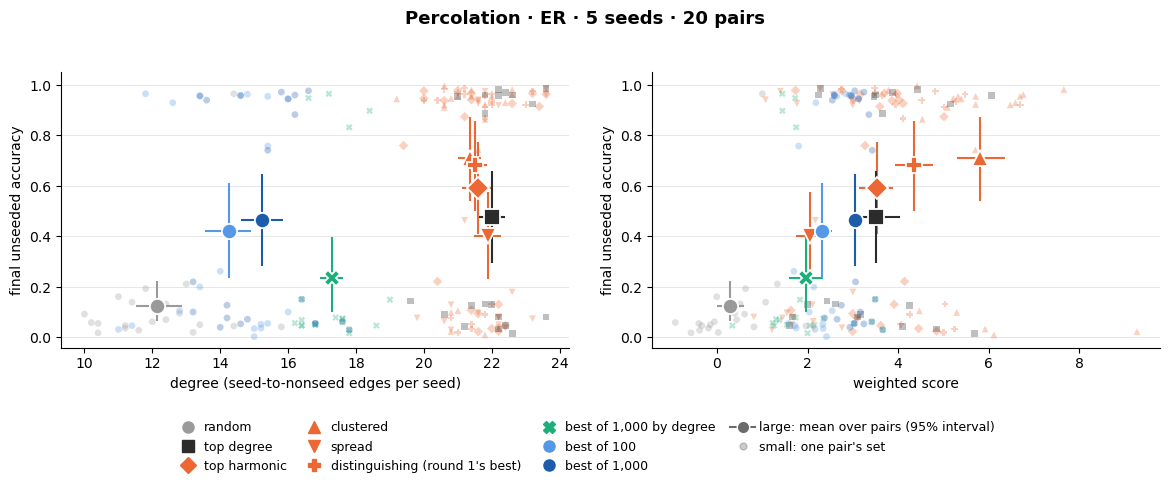

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,12.15,0.29,63.25,"0.13 [0.06, 0.22]",0.05
top degree,20,22.02,3.50,100.00,"0.48 [0.30, 0.66]",0.45
top harmonic,20,21.58,3.54,100.00,"0.59 [0.41, 0.77]",0.60
clustered,20,21.35,5.80,100.00,"0.71 [0.54, 0.87]",0.75
spread,20,21.89,2.05,98.75,"0.40 [0.23, 0.58]",0.35
distinguishing (round 1's best),20,21.52,4.34,100.00,"0.68 [0.50, 0.86]",0.70
"best of 1,000 by degree",20,17.28,1.96,97.90,"0.24 [0.10, 0.40]",0.20
best of 100,20,14.26,2.32,99.75,"0.42 [0.24, 0.61]",0.40
"best of 1,000",20,15.23,3.05,100.00,"0.47 [0.28, 0.65]",0.45


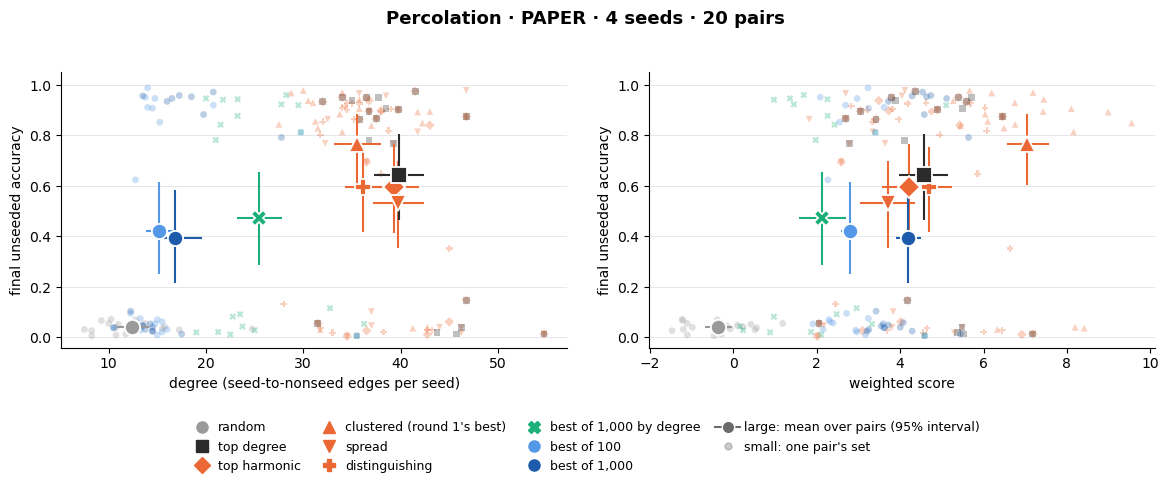

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,12.38,-0.36,39.05,"0.04 [0.03, 0.05]",0.00
top degree,20,39.83,4.57,100.00,"0.64 [0.46, 0.81]",0.70
top harmonic,20,39.33,4.22,99.90,"0.60 [0.41, 0.77]",0.65
clustered (round 1's best),20,35.51,7.05,100.00,"0.77 [0.61, 0.88]",0.85
spread,20,39.76,3.70,99.80,"0.53 [0.36, 0.70]",0.60
distinguishing,20,36.14,4.69,100.00,"0.60 [0.42, 0.76]",0.65
"best of 1,000 by degree",20,25.41,2.13,97.60,"0.47 [0.29, 0.66]",0.50
best of 100,20,15.16,2.79,99.40,"0.42 [0.25, 0.61]",0.45
"best of 1,000",20,16.84,4.20,100.00,"0.39 [0.21, 0.58]",0.40


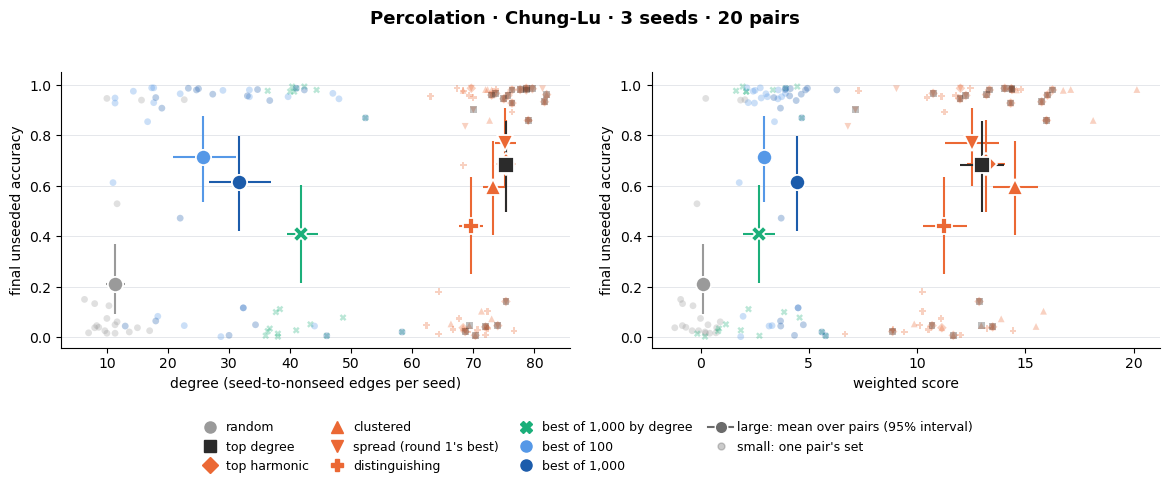

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,11.32,0.11,59.40,"0.21 [0.09, 0.37]",0.20
top degree,20,75.35,13.02,100.00,"0.68 [0.49, 0.86]",0.70
top harmonic,20,75.28,13.17,100.00,"0.69 [0.50, 0.86]",0.70
clustered,20,73.28,14.54,100.00,"0.59 [0.41, 0.78]",0.60
spread (round 1's best),20,75.25,12.52,100.00,"0.77 [0.60, 0.91]",0.80
distinguishing,20,69.68,11.24,100.00,"0.44 [0.25, 0.64]",0.45
"best of 1,000 by degree",20,41.78,2.69,98.60,"0.41 [0.22, 0.60]",0.40
best of 100,20,25.78,2.91,99.55,"0.71 [0.54, 0.88]",0.75
"best of 1,000",20,31.57,4.45,100.00,"0.61 [0.42, 0.80]",0.60


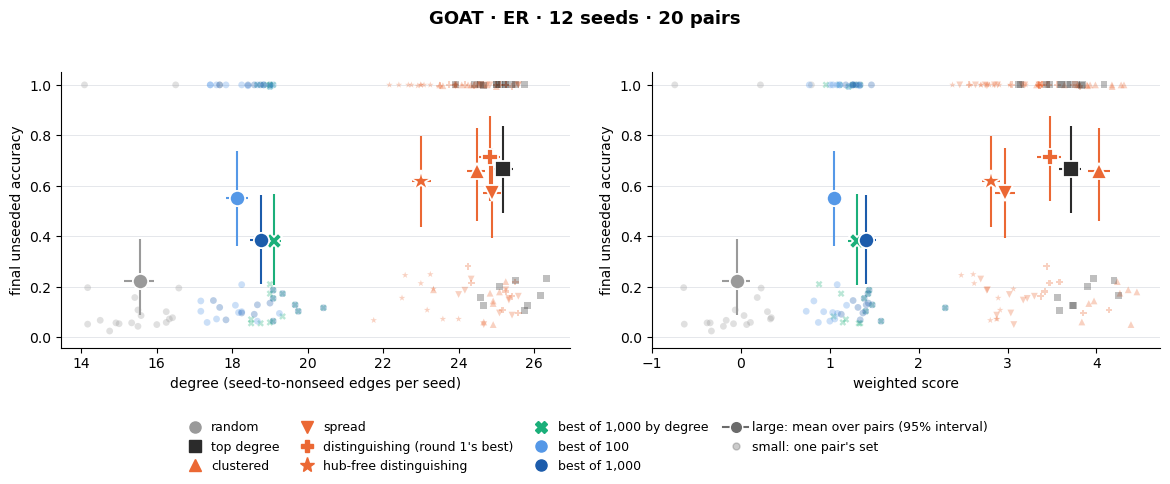

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,15.55,-0.05,48.60,"0.22 [0.09, 0.39]",0.15
top degree,20,25.19,3.71,100.00,"0.67 [0.49, 0.84]",0.60
clustered,20,24.48,4.03,100.00,"0.66 [0.46, 0.83]",0.60
spread,20,24.88,2.97,100.00,"0.57 [0.39, 0.75]",0.50
distinguishing (round 1's best),20,24.83,3.47,100.00,"0.71 [0.54, 0.88]",0.65
hub-free distinguishing,20,23.01,2.81,100.00,"0.62 [0.44, 0.80]",0.55
"best of 1,000 by degree",20,19.10,1.31,99.90,"0.38 [0.21, 0.57]",0.30
best of 100,20,18.12,1.05,99.25,"0.55 [0.36, 0.74]",0.50
"best of 1,000",20,18.76,1.40,100.00,"0.39 [0.21, 0.56]",0.30


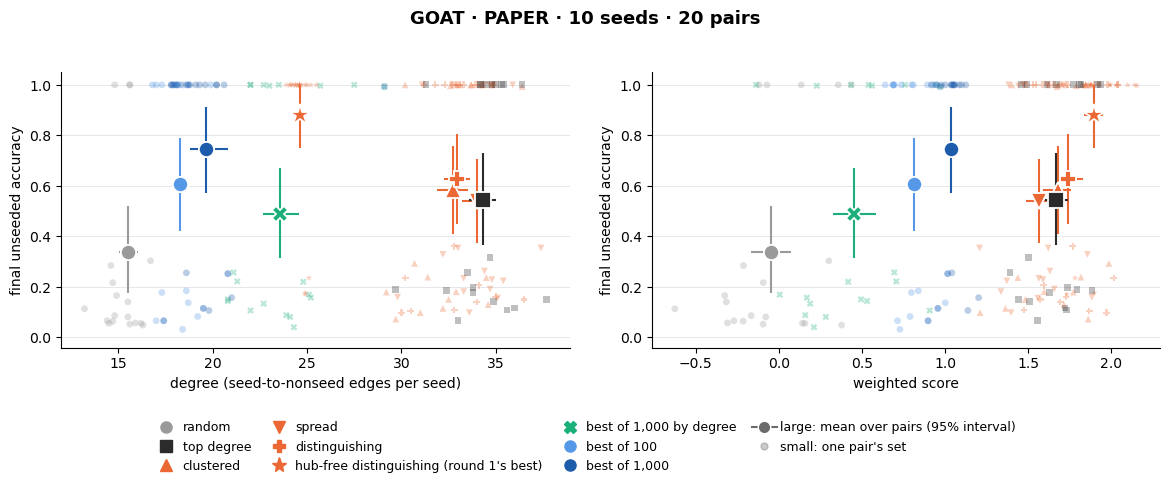

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,15.48,-0.05,38.15,"0.34 [0.18, 0.52]",0.25
top degree,20,34.31,1.67,100.00,"0.55 [0.37, 0.73]",0.45
clustered,20,32.73,1.68,100.00,"0.58 [0.41, 0.76]",0.50
spread,20,33.98,1.56,100.00,"0.54 [0.37, 0.71]",0.40
distinguishing,20,32.95,1.74,100.00,"0.63 [0.45, 0.81]",0.55
hub-free distinguishing (round 1's best),20,24.62,1.89,100.00,"0.88 [0.75, 1.00]",0.85
"best of 1,000 by degree",20,23.58,0.45,92.05,"0.49 [0.32, 0.67]",0.40
best of 100,20,18.26,0.81,99.45,"0.61 [0.42, 0.79]",0.55
"best of 1,000",20,19.65,1.03,100.00,"0.75 [0.57, 0.91]",0.70


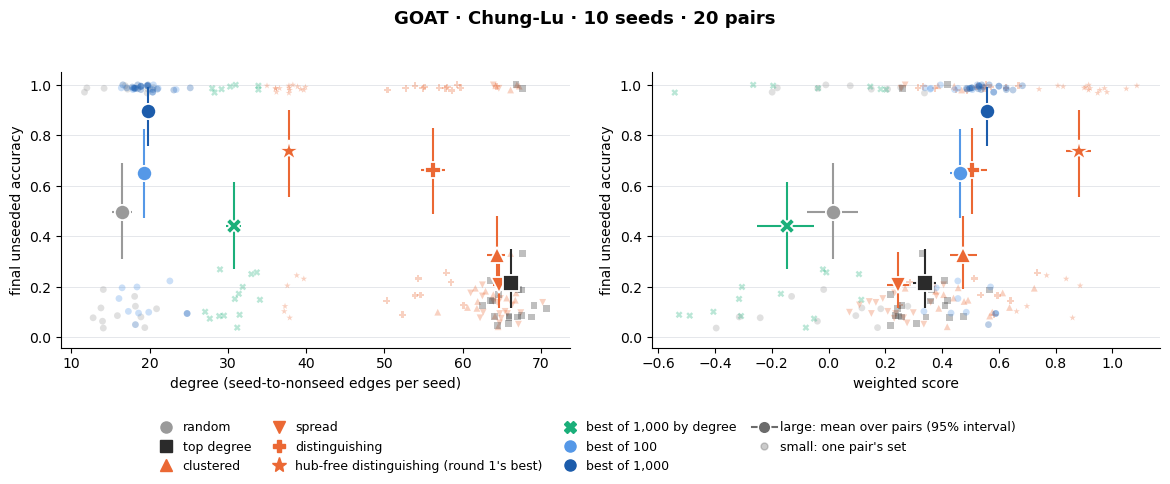

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,16.44,0.02,55.25,"0.50 [0.31, 0.69]",0.45
top degree,20,66.18,0.34,96.85,"0.22 [0.12, 0.35]",0.10
clustered,20,64.31,0.48,99.35,"0.33 [0.19, 0.48]",0.20
spread,20,64.67,0.25,90.45,"0.21 [0.12, 0.34]",0.10
distinguishing,20,56.18,0.51,99.85,"0.66 [0.49, 0.83]",0.60
hub-free distinguishing (round 1's best),20,37.80,0.88,100.00,"0.74 [0.55, 0.90]",0.70
"best of 1,000 by degree",20,30.72,-0.15,25.95,"0.44 [0.27, 0.62]",0.35
best of 100,20,19.26,0.46,99.55,"0.65 [0.47, 0.82]",0.60
"best of 1,000",20,19.76,0.56,100.00,"0.90 [0.76, 0.99]",0.90


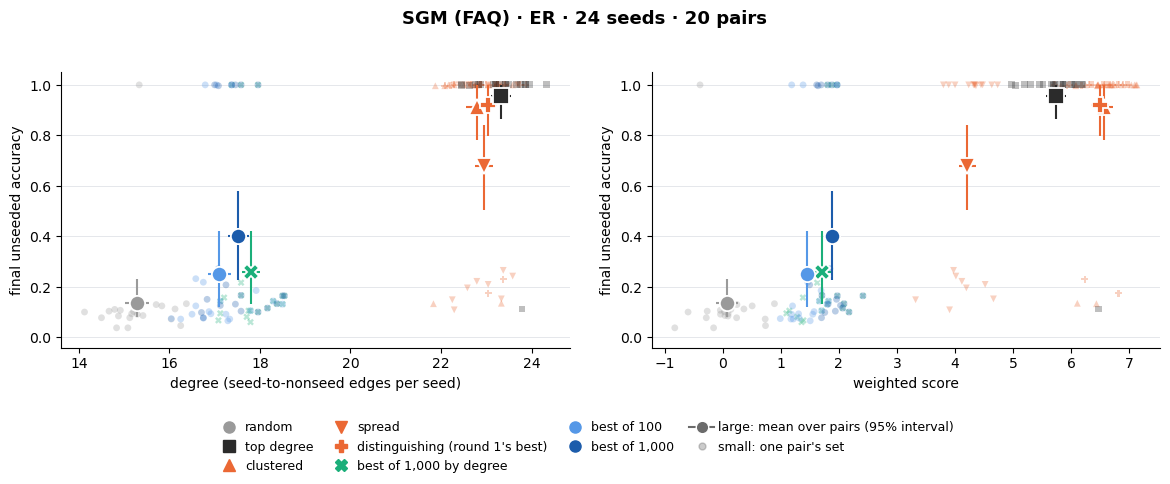

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,15.28,0.07,55.20,"0.14 [0.08, 0.23]",0.05
top degree,20,23.32,5.74,100.00,"0.96 [0.87, 1.00]",0.95
clustered,20,22.79,6.56,100.00,"0.91 [0.78, 1.00]",0.90
spread,20,22.95,4.22,100.00,"0.68 [0.50, 0.84]",0.60
distinguishing (round 1's best),20,23.04,6.50,100.00,"0.92 [0.80, 1.00]",0.90
"best of 1,000 by degree",20,17.80,1.72,99.90,"0.26 [0.13, 0.42]",0.15
best of 100,20,17.10,1.46,99.65,"0.25 [0.12, 0.42]",0.15
"best of 1,000",20,17.52,1.88,100.00,"0.40 [0.23, 0.58]",0.30


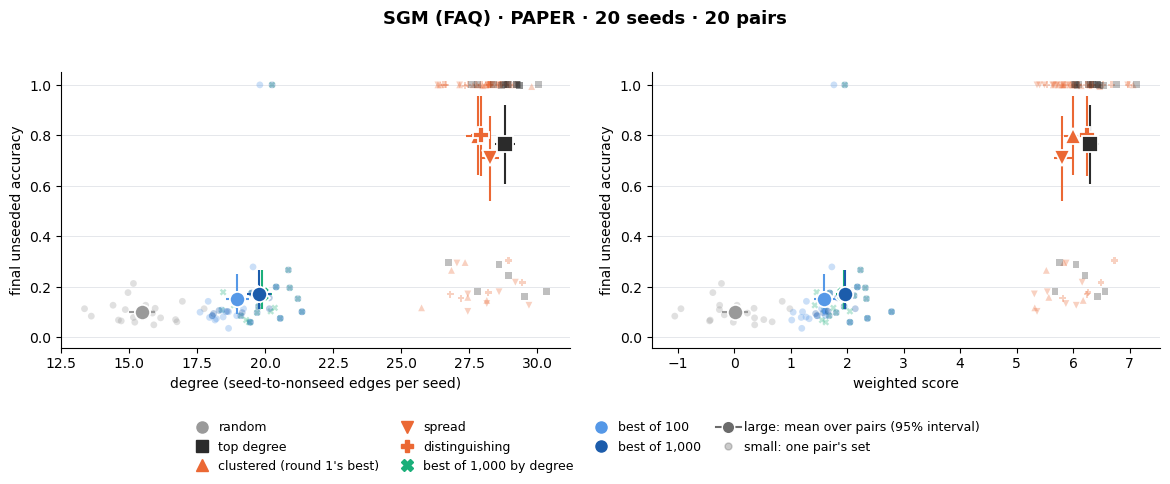

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,15.46,0.01,52.95,"0.10 [0.09, 0.12]",0.00
top degree,20,28.83,6.30,100.00,"0.77 [0.61, 0.92]",0.70
clustered (round 1's best),20,27.81,6.00,100.00,"0.80 [0.64, 0.96]",0.75
spread,20,28.27,5.80,100.00,"0.71 [0.54, 0.88]",0.65
distinguishing,20,27.94,6.25,100.00,"0.80 [0.64, 0.96]",0.75
"best of 1,000 by degree",20,19.89,1.95,100.00,"0.17 [0.11, 0.27]",0.05
best of 100,20,18.96,1.60,99.60,"0.15 [0.09, 0.25]",0.05
"best of 1,000",20,19.77,1.96,100.00,"0.17 [0.11, 0.27]",0.05


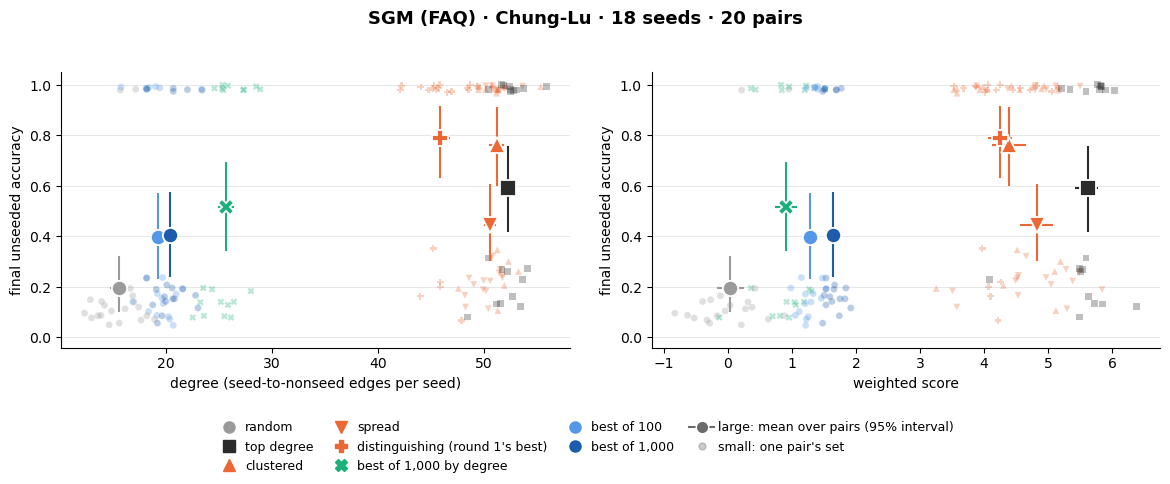

,sets,mean degree,mean score,median score percentile,mean accuracy,success rate
rule,,,,,,
random,20,15.49,0.04,49.50,"0.20 [0.10, 0.32]",0.10
top degree,20,52.34,5.62,100.00,"0.59 [0.42, 0.76]",0.50
clustered,20,51.21,4.40,100.00,"0.76 [0.60, 0.91]",0.70
spread,20,50.58,4.83,100.00,"0.45 [0.30, 0.61]",0.30
distinguishing (round 1's best),20,45.91,4.24,100.00,"0.79 [0.63, 0.92]",0.75
"best of 1,000 by degree",20,25.62,0.91,97.15,"0.52 [0.34, 0.69]",0.45
best of 100,20,19.21,1.29,99.60,"0.40 [0.23, 0.57]",0.30
"best of 1,000",20,20.34,1.64,100.00,"0.40 [0.24, 0.58]",0.30


In [10]:
for algorithm, model in scatter_settings:
    frame = scatter_frame(algorithm, model, SCATTER_INCLUDE_RANDOM)
    fig, _ = BN.draw_seed_scatter(frame, algorithm, model, scatter_budgets[(algorithm, model)],
                                  best[(algorithm, model)], SCATTER_X, summary=SCATTER_SUMMARY,
                                  n_bins=SCATTER_N_BINS)
    plt.show()
    display(BN.rule_summary(frame, best[(algorithm, model)]))

### 7.2 Compared with top degree on the same pair

Each rule's degree, score and accuracy minus top degree's, on the same pair at the same budget. Top degree itself is left out, and random is left out unless `SCATTER_PAIRED_INCLUDE_RANDOM = True`.
- **Above zero:** the rule matched better than top degree on that pair. A large marker above zero means the rule beats top degree on average.
- **Left of zero on the left panel:** fewer seed-to-nonseed edges than top degree.

Best-of-N sets typically sit far to the left: they give up degree. The question is whether they still land above zero.

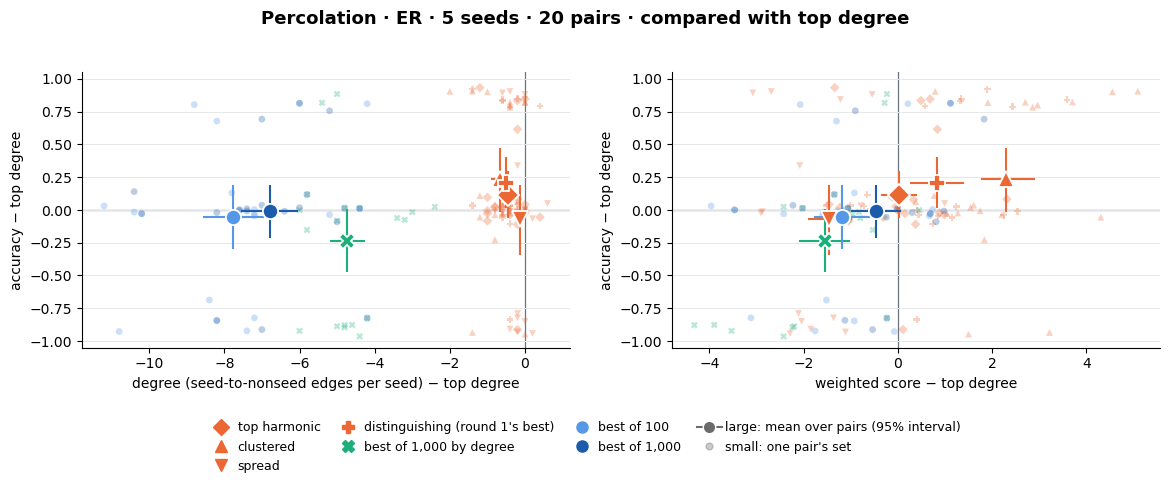

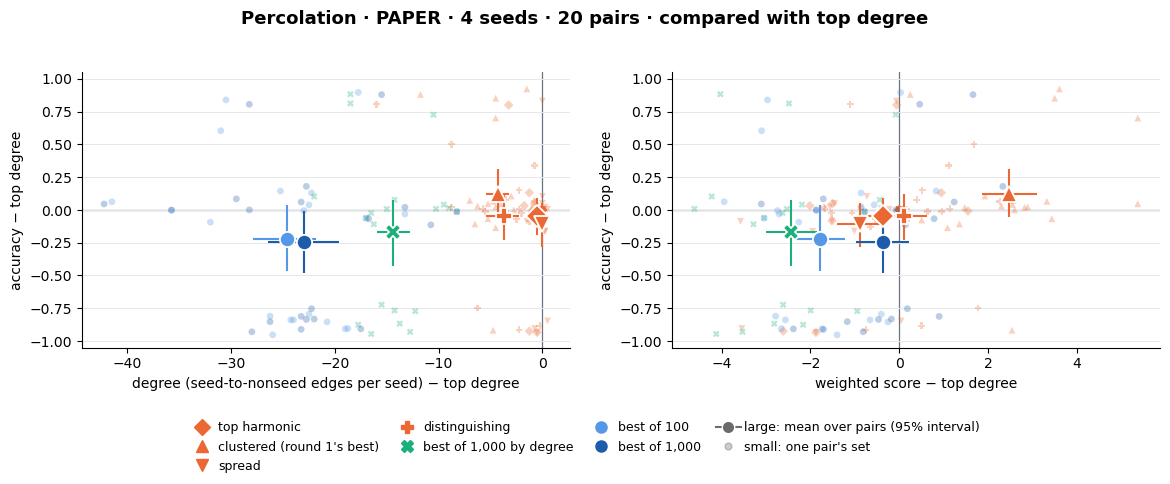

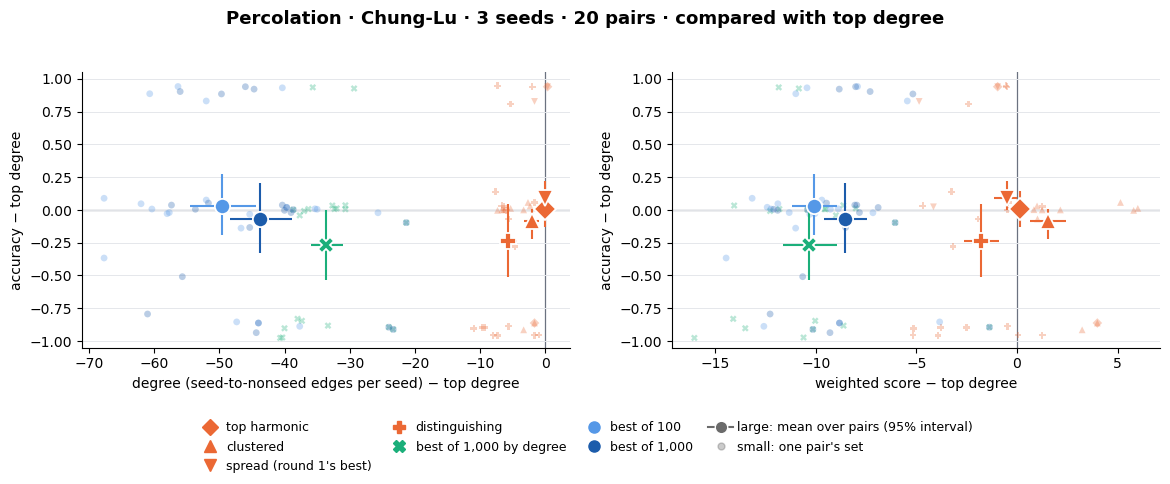

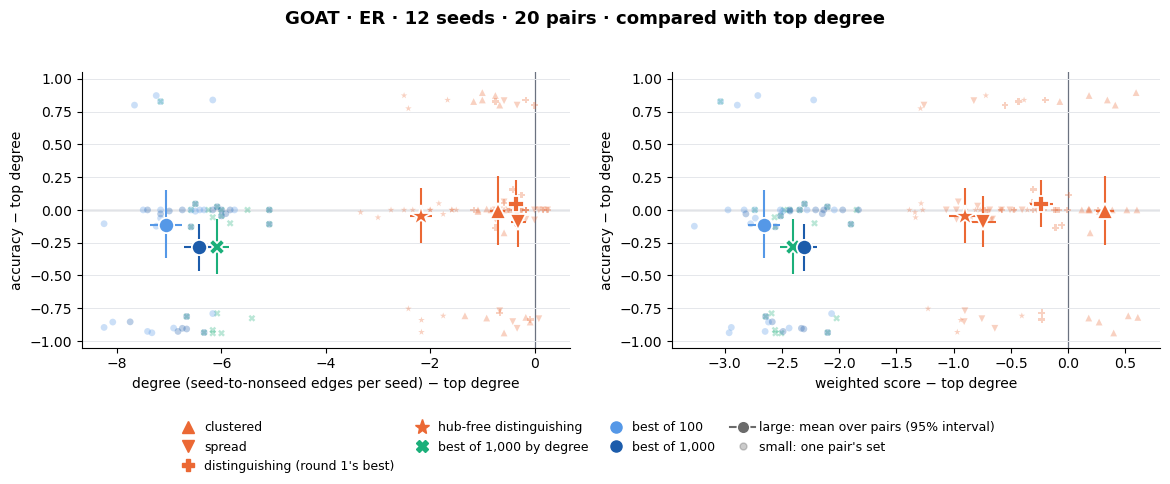

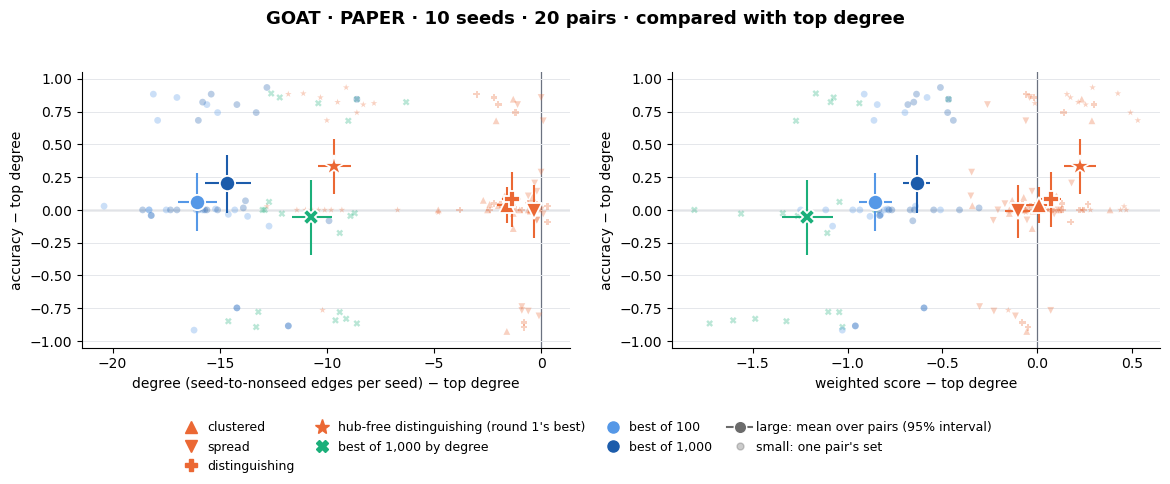

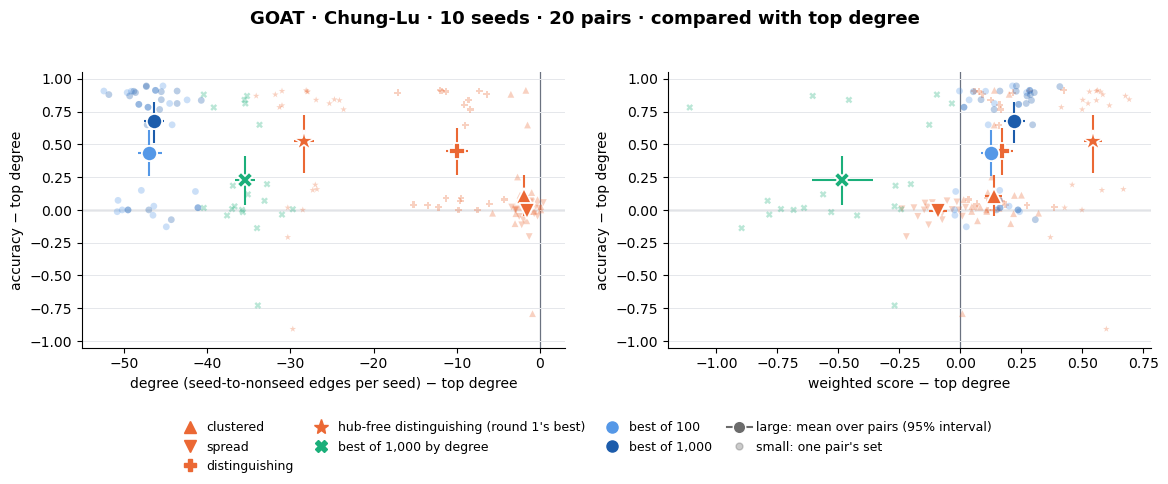

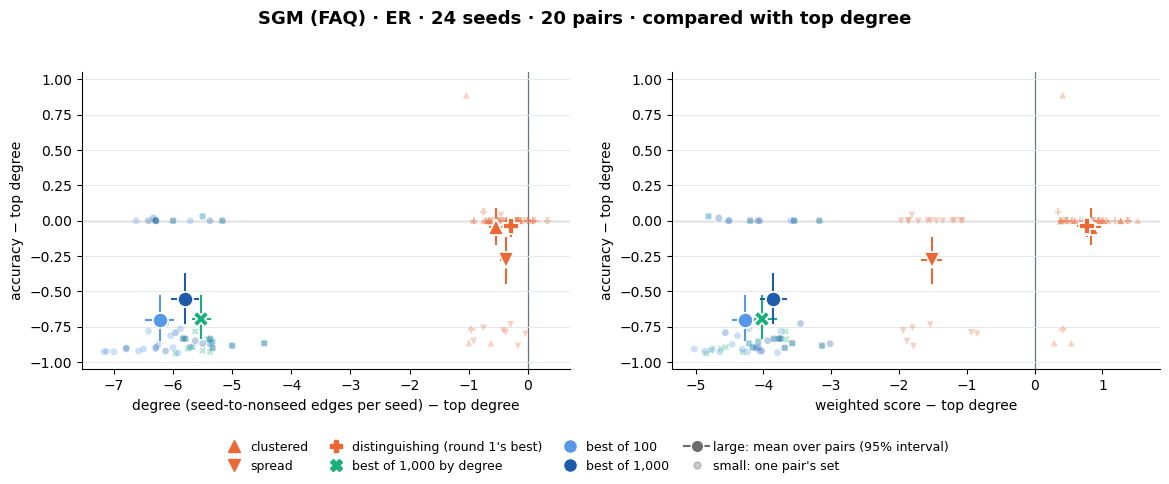

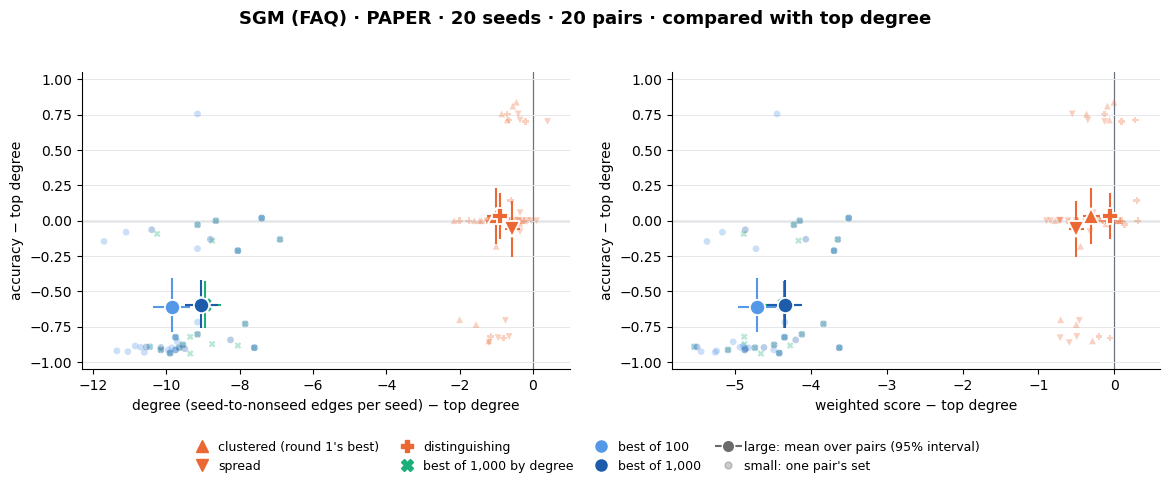

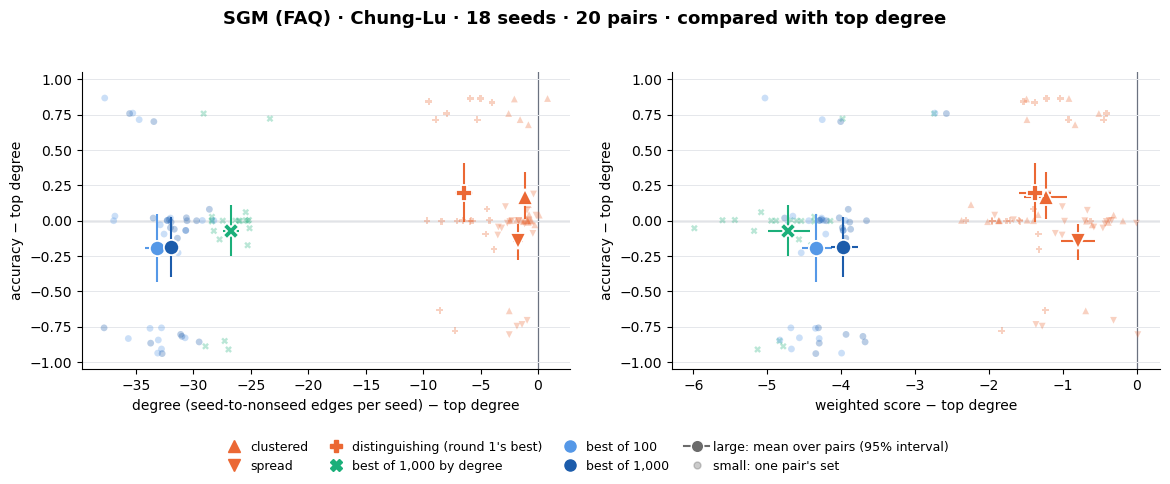

In [11]:
changes_tables = []
for algorithm, model in scatter_settings:
    frame = scatter_frame(algorithm, model, True)
    changes = BN.against_top_degree(frame, [*SCATTER_X, 'accuracy'], include_random=SCATTER_PAIRED_INCLUDE_RANDOM)
    fig, _ = BN.draw_seed_scatter(changes, algorithm, model, scatter_budgets[(algorithm, model)],
                                  best[(algorithm, model)], SCATTER_X, paired=True, summary=SCATTER_SUMMARY,
                                  n_bins=SCATTER_N_BINS)
    plt.show()
    table = BN.top_degree_changes(frame, SCATTER_X, best[(algorithm, model)], SCATTER_PAIRED_INCLUDE_RANDOM)
    changes_tables.append(table.assign(algorithm=BN.ALGORITHM_LABELS[algorithm], model=BN.MODEL_LABELS[model],
                                       budget=scatter_budgets[(algorithm, model)]))

### 7.3 Each rule against top degree, in numbers

These are the large markers of section 7.2. For each rule, on the same pairs:
- **Change in degree, score and accuracy:** the mean of the rule minus top degree, with a 95% bootstrap interval over pairs.
- **Succeeds where top degree fails / fails where top degree succeeds:** the number of pairs where only one of the two succeeded.

In [12]:
if changes_tables:
    display(pd.concat(changes_tables).reset_index().set_index(['algorithm', 'model', 'budget', 'rule']))
else:
    print('Run the plotting cell above first.')

pairs  \
algorithm   model    budget rule                                              
Percolation ER       5      top harmonic                                 20   
                            clustered                                    20   
                            spread                                       20   
                            distinguishing (round 1's best)              20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
            PAPER    4      top harmonic                                 20   
                            clustered (round 1's best)                   20   
                            spread                                       20   
                            distinguishing                               20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
            Chung-Lu 3      top harmonic                                 20   
                            clustered                                    20   
                            spread (round 1's best)                      20   
                            distinguishing                               20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
GOAT        ER       12     clustered                                    20   
                            spread                                       20   
                            distinguishing (round 1's best)              20   
                            hub-free distinguishing                      20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
            PAPER    10     clustered                                    20   
                            spread                                       20   
                            distinguishing                               20   
                            hub-free distinguishing (round 1's best)     20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
            Chung-Lu 10     clustered                                    20   
                            spread                                       20   
                            distinguishing                               20   
                            hub-free distinguishing (round 1's best)     20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
SGM (FAQ)   ER       24     clustered                                    20   
                            spread                                       20   
                            distinguishing (round 1's best)              20   
                            best of 1,000 by degree                      20   
                            best of 100                                  20   
                            best of 1,000                                20   
            PAPER    20     clustered (round 1's best)                   20   
                            spread       

## 8. GOAT at r = 100 against r = 300

GOAT's transport regulariser r sets how soft the matching steps are. Round 1 used r = 300 on PAPER and Chung–Lu, where r = 100 often stalls: the solver stops within 3 iterations. graspologic's default is r = 100, which is what a typical user would run.

This section reruns GOAT at r = 100 with everything else held fixed: the same pairs, seed sets and budgets, and round 1's solver seeds. That makes the two regularisers directly comparable, set by set. r = 300 stays the main setting.

### 8.1 Success by budget

The left column repeats section 2 at r = 300 and the right column shows r = 100. The styles are as in section 2. "Round 1's best" is chosen separately at each r, after the fact.

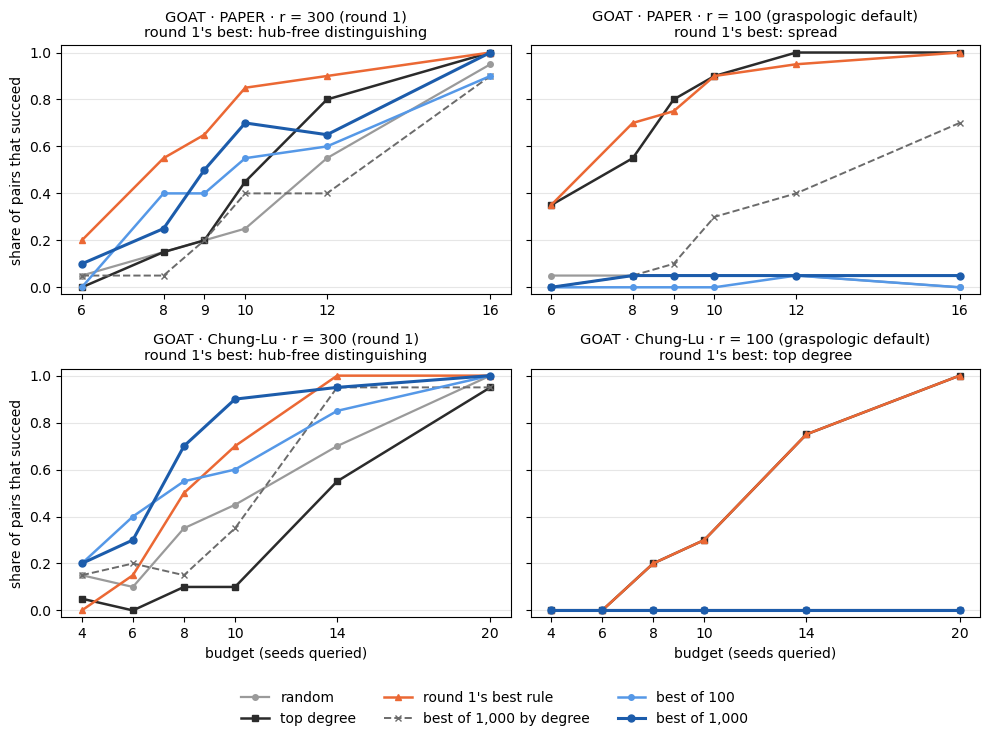

In [13]:
ev300_r, ev100 = BN.r100_evaluations()
runs100 = BN.read_r100()
queries100 = BN.queries_needed(ev100)
best100 = BN.round1_best(ev100, queries100)
columns = [('r = 300 (round 1)', BN.success_curves(ev300_r), best),
           (f'r = {BN.R100_REGULARIZER} (graspologic default)', BN.success_curves(ev100), best100)]
r100_models = [m for m in BN.R100_MODELS if m in set(ev100['model'])]
fig, axes = plt.subplots(len(r100_models), 2, figsize=(10, 3.7 * len(r100_models)), squeeze=False, sharey=True)
for row, model in enumerate(r100_models):
    for column, (label, curves_r, best_r) in enumerate(columns):
        ax = axes[row, column]
        part = curves_r[curves_r['model'] == model]
        for key, style in STYLE.items():
            rule = best_r[('goat', model)] if key == 'round1_best' else key
            line = part[part['rule'] == rule].sort_values('budget')
            if not line.empty:
                ax.plot(line['budget'], line['success'], **{k: v for k, v in style.items() if k != 'label'})
        ax.set_title(f"GOAT · {BN.MODEL_LABELS[model]} · {label}\n"
                     f"round 1's best: {BN.rule_label(best_r[('goat', model)])}", fontsize=10.5)
        ax.set_xticks(sorted(part['budget'].unique()))
        ax.set_ylim(-0.03, 1.03)
        ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
        ax.set_axisbelow(True)
    axes[row, 0].set_ylabel('share of pairs that succeed')
for ax in axes[-1]:
    ax.set_xlabel('budget (seeds queried)')
handles = [Line2D([0], [0], **{k: v for k, v in style.items()}) for style in STYLE.values()]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

### 8.2 Each rule at both regularisers

For every rule, on the same pairs:
- **Mean success over round 1's budgets** at r = 300 and r = 100. "Change" is r = 100 minus r = 300, with a 95% bootstrap interval over pairs.
- **Mean queries needed** at each r.
- **Stalled:** the share of runs that stopped within 3 iterations.

If best of N's edge at r = 300 holds at r = 100, the conclusions do not hinge on the tuned regulariser.

In [14]:
display(BN.regularizer_table(ev300_r, ev100, runs100))

pairs  mean success, r = 300  \
model    rule                                                    
PAPER    random                      20                   0.36   
         top degree                  20                   0.43   
         clustered                   20                   0.53   
         spread                      20                   0.49   
         distinguishing              20                   0.56   
         hub-free distinguishing     20                   0.69   
         best of 100                 20                   0.48   
         best of 1,000               20                   0.53   
         best of 1,000 by degree     20                   0.33   
Chung-Lu random                      20                   0.46   
         top degree                  20                   0.29   
         clustered                   20                   0.34   
         spread                      20                   0.27   
         distinguishing              20                   0.50   
         hub-free distinguishing     20                   0.56   
         best of 100                 20                   0.60   
         best of 1,000               20                   0.68   
         best of 1,000 by degree     20                   0.46   

                                  mean success, r = 100                change  \
model    rule                                                                   
PAPER    random                                    0.04  -0.32 [-0.46, -0.17]   
         top degree                                0.77  +0.33 [+0.28, +0.38]   
         clustered                                 0.62  +0.09 [-0.01, +0.18]   
         spread                                    0.78  +0.28 [+0.20, +0.37]   
         distinguishing                            0.59  +0.03 [-0.12, +0.18]   
         hub-free distinguishing                   0.02  -0.68 [-0.79, -0.54]   
         best of 100                               0.01  -0.47 [-0.57, -0.37]   
         best of 1,000                             0.04  -0.49 [-0.62, -0.36]   
         best of 1,000 by degree                   0.26  -0.07 [-0.17, +0.02]   
Chung-Lu random                                    0.00  -0.46 [-0.57, -0.36]   
         top degree                                0.37  +0.08 [+0.04, +0.12]   
         clustered                                 0.26  -0.08 [-0.19, +0.03]   
         spread                                    0.24  -0.03 [-0.12, +0.05]   
         distinguishing                            0.07  -0.43 [-0.53, -0.33]   
         hub-free distinguishing                   0.00  -0.56 [-0.63, -0.48]   
         best of 100                               0.00  -0.60 [-0.69, -0.51]   
         best of 1,000                             0.00  -0.68 [-0.75, -0.59]   
         best of 1,000 by degree                   0.00  -0.46 [-0.52, -0.39]   

                                  queries needed, r = 300  \
model    rule                                               
PAPER    random                                      12.9   
         top degree                                  11.2   
         clustered                                   10.4   
         spread                                      10.9   
         distinguishing                              10.3   
         hub-free distinguishing                      8.8   
         best of 100                                  9.9   
         best of 1,000                                9.9   
         best of 1,000 by degree                     11.3   
Chung-Lu random                                      11.7   
         top degree                                  15.9   
         clustered                                   14.5   
         spread                                      16.3   
         distinguishing                              10.6   
         hub-free distinguishing                      9.9   
         best of 100                                  8

### 8.3 Head to head at r = 100

These are the pair-by-pair comparisons of section 4, recomputed at r = 100.

In [15]:
comparisons100 = BN.comparison_table(ev100, queries100, best100)
for rule in ['best of 1,000', 'best of 100']:
    print(rule.capitalize(), f'against the others at r = {BN.R100_REGULARIZER}:')
    display(comparisons100.xs(rule, level='rule'))

Best of 1,000 against the others at r = 100:


pairs  \
algorithm model    against                              
GOAT      PAPER    random                          20   
                   top degree                      20   
                   spread (round 1's best)         20   
                   best of 1,000 by degree         20   
          Chung-Lu random                          20   
                   top degree (round 1's best)     20   
                   best of 1,000 by degree         20   

                                               needs fewer / same / more queries  \
algorithm model    against                                                         
GOAT      PAPER    random                                             3 / 16 / 1   
                   top degree                                         1 / 1 / 18   
                   spread (round 1's best)                            1 / 1 / 18   
                   best of 1,000 by degree                            2 / 4 / 14   
          Chung-Lu random                                             0 / 20 / 0   
                   top degree (round 1's best)                        0 / 0 / 20   
                   best of 1,000 by degree                            0 / 20 / 0   

                                                     p  \
algorithm model    against                               
GOAT      PAPER    random                       0.6250   
                   top degree                   0.0001   
                   spread (round 1's best)      0.0001   
                   best of 1,000 by degree      0.0042   
          Chung-Lu random                          NaN   
                   top degree (round 1's best)  0.0000   
                   best of 1,000 by degree         NaN   

                                                      change in queries  \
algorithm model    against                                                
GOAT      PAPER    random                          -0.95 [-3.25, +1.50]   
                   top degree                    +10.25 [+8.05, +12.15]   
                   spread (round 1's best)       +10.15 [+7.85, +12.05]   
                   best of 1,000 by degree         +4.75 [+2.80, +6.75]   
          Chung-Lu random                          +0.00 [+0.00, +0.00]   
                   top degree (round 1's best)  +12.50 [+10.60, +14.40]   
                   best of 1,000 by degree         +0.00 [+0.00, +0.00]   

                                               change in mean success  
algorithm model    against                                             
GOAT      PAPER    random                        +0.00 [-0.11, +0.08]  
                   top degree                    -0.72 [-0.83, -0.61]  
                   spread (round 1's best)       -0.73 [-0.85, -0.60]  
                   best of 1,000 by degree       -0.22 [-0.30, -0.14]  
          Chung-Lu random                        +0.00 [+0.00, +0.00]  
                   top degree (round 1's best)   -0.37 [-0.44, -0.31]  
                   best of 1,000 by degree       +0.00 [+0.00, +0.00]

Best of 100 against the others at r = 100:


pairs  \
algorithm model    against                              
GOAT      PAPER    random                          20   
                   top degree                      20   
                   spread (round 1's best)         20   
          Chung-Lu random                          20   
                   top degree (round 1's best)     20   

                                               needs fewer / same / more queries  \
algorithm model    against                                                         
GOAT      PAPER    random                                             1 / 18 / 1   
                   top degree                                         0 / 0 / 20   
                   spread (round 1's best)                            0 / 0 / 20   
          Chung-Lu random                                             0 / 20 / 0   
                   top degree (round 1's best)                        0 / 0 / 20   

                                                  p        change in queries  \
algorithm model    against                                                     
GOAT      PAPER    random                       1.0     +0.30 [-1.20, +2.10]   
                   top degree                   0.0  +11.50 [+10.15, +12.65]   
                   spread (round 1's best)      0.0   +11.40 [+9.90, +12.65]   
          Chung-Lu random                       NaN     +0.00 [+0.00, +0.00]   
                   top degree (round 1's best)  0.0  +12.50 [+10.60, +14.40]   

                                               change in mean success  
algorithm model    against                                             
GOAT      PAPER    random                        -0.03 [-0.12, +0.03]  
                   top degree                    -0.76 [-0.86, -0.65]  
                   spread (round 1's best)       -0.77 [-0.87, -0.65]  
          Chung-Lu random                        +0.00 [+0.00, +0.00]  
                   top degree (round 1's best)   -0.37 [-0.44, -0.31]